# kNN nach Vorlesung und DataCamp

**Frage:** Können wir vorhersagen, welche Teilnehmenden ihren Job wechseln wollen (`job_change`)?

Dieses Notebook nutzt nur Methoden aus dem Foliensatz **03 Supervised Learning Foundations** und aus dem DataCamp-Kurs **Supervised Learning with scikit-learn**. Encoding, Skalierung und Pipeline stammen aus DataCamp Kapitel 4, das laut Folie 77 zum Kurs gehört.

| Schritt | Was passiert | Quelle |
|---|---|---|
| 1 | Aufgabe festlegen | Folien 6 bis 8, DataCamp Kap. 1 |
| 2 | Daten laden, Voraussetzungen prüfen | DataCamp Kap. 1 |
| 3 | Kategorien in Zahlen umwandeln | DataCamp Kap. 4 |
| 4 | Baseline bestimmen | Folien 20, 40, 41 |
| 5 | Validierungsdaten abtrennen | Folien 17 bis 20, DataCamp Kap. 1 |
| 6 | Erstes Modell mit Skalierung | Folien 14, 16, DataCamp Kap. 1 und 4 |
| 7 | Das beste k finden | Folien 21 bis 23, DataCamp Kap. 1 |
| 8 | Cross-Validation | Folien 31 bis 36, DataCamp Kap. 2 |
| 9 | Schwelle wählen: ROC, AUC und Kosten | Folien 57 bis 71 |
| 10 | Abschlussprüfung auf dem Testset | Folien 42 bis 52, 63 bis 69 |
| 11 | Fazit | Folie 76 |

**Die wichtigste Regel:** Alle Entscheidungen (k und Schwelle) fallen ohne das Testset. Das Testset wird erst in Schritt 10 und nur einmal benutzt.

## 0. Setup

Alle Werkzeuge werden hier geladen. `RANDOM_STATE` legt den Zufall fest, damit jede Ausführung dieselben Ergebnisse liefert.

In [2]:
# Grundwerkzeuge: numpy für Zahlen, pandas für Tabellen, matplotlib für Grafiken
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Daten aufteilen und Cross-Validation (DataCamp Kap. 1 und 2)
from sklearn.model_selection import train_test_split, KFold, cross_val_score
# Das kNN-Modell (DataCamp Kap. 1)
from sklearn.neighbors import KNeighborsClassifier
# Skalierung und Pipeline (DataCamp Kap. 4)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
# Kennzahlen für die Auswertung (DataCamp Kap. 3)
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             roc_curve, roc_auc_score)

# Fester Startwert für den Zufall
RANDOM_STATE = 42

# Einheitliche Farben und ein ruhiges Aussehen für alle Grafiken
BLUE, RED, INK = "#2878D8", "#B22E2E", "#262B31"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#E6E8EB", "axes.axisbelow": True,
    "lines.linewidth": 2, "legend.frameon": False,
})

## 1. Die Aufgabe (Folien 6 bis 8)

**Supervised Learning:** Bei den Trainingsdaten kennen wir die richtige Antwort, und das Modell lernt daraus, sie für neue Personen vorherzusagen.

| Begriff | Bei uns |
|---|---|
| **Target** (Zielvariable, `y`) | `job_change`: 1 = will wechseln, 0 = will nicht wechseln |
| **Features** (`X`) | die 10 Spalten, die das Modell nutzen darf |
| **Art der Aufgabe** | **Klassifikation**, weil das Ziel zwei Kategorien hat |
| **Unit** | eine teilnehmende Person |
| **Decision** | Wen spricht das Recruiting an? |

**Nicht genutzt werden:** `student_id` (nur eine Nummer), `city` (123 Städte, `city_development_index` beschreibt die Stadt schon) und `gender` (Fairness, schon im Imputation-Notebook entfernt).

## 2. Daten laden

Wir laden die zwei fertigen Dateien aus `missing_values_imputation.ipynb`. Die Daten sind dort schon in **Training (80 %)** und **Test (20 %)** geteilt worden. Das ist unser **Holdout-Split** (Folien 17 bis 20): Das Testset bleibt bis zur Abschlussprüfung verschlossen.

In [3]:
# Die zwei Dateien laden. Pickle behält die Datentypen aus fix_data.ipynb
train = pd.read_pickle("customer_train_final_train.pkl")
test = pd.read_pickle("customer_train_final_test.pkl")

# Features: alles außer ID, Stadt und Zielvariable
drop_cols = ["student_id", "city", "job_change"]
X_train = train.drop(columns=drop_cols)
X_test = test.drop(columns=drop_cols)

# Target: True/False wird zu 1/0
y_train = train["job_change"].astype(int)
y_test = test["job_change"].astype(int)

print("Training:", X_train.shape, "| Anteil Wechsel:", round(y_train.mean(), 3))
print("Test:    ", X_test.shape, "| Anteil Wechsel:", round(y_test.mean(), 3))
X_train.head(3)

Training: (15326, 10) | Anteil Wechsel: 0.249
Test:     (3832, 10) | Anteil Wechsel: 0.249


,city_development_index,relevant_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours
17855,0.624023,True,no_enrollment,Graduate,STEM,10,50-99,Pvt Ltd,1,90
17664,0.919922,False,no_enrollment,Primary School,No Major,5,Unknown,Unknown,never,15
13404,0.895996,True,no_enrollment,Graduate,STEM,12,1000-4999,NGO,>4,36


### Voraussetzungen (DataCamp Kap. 1)

Bevor ein Modell trainiert werden kann, müssen die Daten drei Bedingungen erfüllen:

In [4]:
# 1. Keine fehlenden Werte
print("Fehlende Werte:", int(X_train.isna().sum().sum() + X_test.isna().sum().sum()))
# 2. Daten als DataFrame oder NumPy-Array
print("Datentyp:", type(X_train).__name__)
# 3. Alles numerisch: Diese Spalten sind noch Text oder True/False und werden in Schritt 3 umgewandelt
print("Noch keine Zahlen:", list(X_train.select_dtypes(exclude="number").columns))

Fehlende Werte: 0
Datentyp: DataFrame
Noch keine Zahlen: ['relevant_experience', 'enrolled_university', 'education_level', 'major_discipline', 'experience', 'company_size', 'company_type', 'last_new_job']


**Ergebnis:** Die Bedingungen 1 und 2 sind erfüllt. 8 Spalten sind aber noch keine Zahlen: 7 Textspalten und `relevant_experience` mit True/False. Das ändert Schritt 3.

## 3. Kategorien in Zahlen umwandeln (DataCamp Kap. 4)

kNN vergleicht Personen über **Abstände**. Mit Text kann man aber nicht rechnen. Je nach Spalte nutzen wir einen von zwei Wegen:

| Variable | Typ | Umwandlung | Spalten danach |
|---|---|---|---|
| `city_development_index` | numerisch | bleibt | 1 |
| `training_hours` | numerisch | bleibt | 1 |
| `relevant_experience` | binär (ja/nein) | wird 1/0 | 1 |
| `education_level` | Kategorie mit Reihenfolge | Rangzahl: Primary School = 0 bis Phd = 4 | 1 |
| `experience` | Kategorie mit Reihenfolge | Rangzahl: <1 = 0 bis >20 = 21 | 1 |
| `last_new_job` | Kategorie mit Reihenfolge | Rangzahl: never = 0 bis >4 = 5 | 1 |
| `enrolled_university` | Kategorie ohne Reihenfolge | Dummy-Variablen (one-hot) | 3 |
| `major_discipline` | Kategorie ohne Reihenfolge | Dummy-Variablen (one-hot) | 7 |
| `company_size` | Kategorie ohne Reihenfolge, wegen "Unknown" | Dummy-Variablen (one-hot) | 9 |
| `company_type` | Kategorie ohne Reihenfolge | Dummy-Variablen (one-hot) | 7 |
| **Summe** | | | **32** |

**Rangzahlen:** Die Reihenfolge wurde schon in `fix_data.ipynb` festgelegt. `.cat.codes` gibt jeder Kategorie ihre Position in dieser Reihenfolge. So liegt "Graduate" (2) näher an "Masters" (3) als an "Primary School" (0).

**Dummy-Variablen:** `pd.get_dummies` macht aus jeder Kategorie eine eigene 0/1-Spalte, wie im DataCamp-Kurs. Bei Firmentypen wäre eine Nummerierung erfunden: Mit Startup = 0, NGO = 1 und Pvt Ltd = 2 wäre Pvt Ltd doppelt so weit von Startup entfernt wie NGO.

In [5]:
ordinal_cols = ["education_level", "experience", "last_new_job"]
nominal_cols = ["enrolled_university", "major_discipline", "company_size", "company_type"]


def encode(X):
    X = X.copy()
    # Ja/Nein wird 1/0
    X["relevant_experience"] = X["relevant_experience"].astype(int)
    # Rangzahlen: Position in der festgelegten Reihenfolge
    for col in ordinal_cols:
        X[col] = X[col].cat.codes
    # Dummy-Variablen: eine 0/1-Spalte je Kategorie
    return pd.get_dummies(X, columns=nominal_cols, dtype=int)


# Dieselbe Funktion für Training und Test, damit beide gleich aufgebaut sind
X_train = encode(X_train)
X_test = encode(X_test)

# Kontrolle: gleiche Spalten in gleicher Reihenfolge, alles numerisch
print("Spalten:", X_train.shape[1], "| Training und Test gleich:", list(X_train.columns) == list(X_test.columns))
print("Noch keine Zahlen:", list(X_train.select_dtypes(exclude="number").columns))

Spalten: 32 | Training und Test gleich: True
Noch keine Zahlen: []


## 4. Baseline (Folien 20, 40, 41)

Was erreicht man ganz ohne Modell? Wer immer "kein Wechsel" sagt, liegt so oft richtig, wie Personen nicht wechseln wollen.

In [6]:
# Anteil der häufigsten Klasse = Accuracy der Regel "immer kein Wechsel"
baseline_accuracy = y_train.value_counts(normalize=True).max()
print(f"Baseline-Accuracy: {baseline_accuracy:.3f}")

Baseline-Accuracy: 0.751


**Ergebnis:** Die Regel "immer kein Wechsel" ist schon zu **75,1 %** richtig, findet aber keine einzige wechselwillige Person. Jedes Modell muss diese Marke übertreffen. Gleichzeitig zeigt sie, dass die Accuracy allein wenig aussagt, wenn eine Klasse selten ist (Folie 41).

## 5. Validierungsdaten abtrennen (Folien 17 bis 20, DataCamp Kap. 1)

Wir wollen k und später die Schwelle auswählen. Dafür müssen wir messen, wie gut ein Modell bei **unbekannten** Personen ist. Das Testset dürfen wir dafür nicht benutzen, sonst wäre die Abschlussprüfung nicht mehr unabhängig.

Darum teilen wir die Trainingsdaten noch einmal, genau wie in DataCamp mit `train_test_split`:

```text
Alle 19.158 Personen
├── Trainingsdaten: 15.326
│   ├── X_fit: 80 %  → damit lernt das Modell
│   └── X_val: 20 %  → damit wählen wir k und die Schwelle
└── Testdaten: 3.832 → Abschlussprüfung in Schritt 10
```

`stratify` sorgt dafür, dass der Anteil der Wechsler in beiden Teilen gleich bleibt. Bei nur 25 % Wechslern ist das wichtig (Folie 20).

In [7]:
# Trainingsdaten teilen: 80 % zum Lernen, 20 % zum Prüfen
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=RANDOM_STATE, stratify=y_train)

print("X_fit:", X_fit.shape, "| Anteil Wechsel:", round(y_fit.mean(), 3))
print("X_val:", X_val.shape, "| Anteil Wechsel:", round(y_val.mean(), 3))

X_fit: (12260, 32) | Anteil Wechsel: 0.249
X_val: (3066, 32) | Anteil Wechsel: 0.25


## 6. Erstes Modell mit Skalierung (Folien 14, 16, DataCamp Kap. 1 und 4)

**Problem:** `training_hours` reicht bis 336, `city_development_index` nur bis 0,95. Ohne Skalierung würden die Trainingsstunden die Abstände fast allein bestimmen.

**Goal:** Alle Features sollen vergleichbar in die Abstandsberechnung eingehen.

**Lösung:** Der `StandardScaler` rechnet jede Spalte um in (Wert − Mittelwert) / Standardabweichung. Danach liegt jede Spalte um 0, und eine typische Abweichung entspricht 1.

**Warum eine Pipeline?** Wie in DataCamp Kap. 4 stecken Scaler und Modell zusammen in einer `Pipeline`. Bei `fit` lernt der Scaler Mittelwert und Standardabweichung nur aus den Lerndaten. Die Prüfdaten werden dann mit genau diesen Werten umgerechnet. So fließt keine Information aus den Prüfdaten ins Lernen.

Die Grammatik ist bei jedem Modell gleich: **erstellen, `fit`, `predict` bzw. `score`.** Als Startwert nehmen wir k = 15 wie auf Folie 14.

In [8]:
def make_knn(k):
    # Erst skalieren, dann kNN: beides wird zusammen gelernt und angewendet
    return Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=k)),
    ])


# 1. erstellen, 2. lernen
knn = make_knn(15)
knn.fit(X_fit, y_fit)

# 3. vorhersagen: die ersten fünf Personen aus den Prüfdaten
print("Vorhersagen für 5 Personen:", knn.predict(X_val.iloc[:5]))
print("Wahre Antworten:           ", y_val.iloc[:5].values)

# .score berechnet die Accuracy: richtige Vorhersagen geteilt durch alle
print(f"k = 15, Accuracy auf X_val: {knn.score(X_val, y_val):.3f}")

Vorhersagen für 5 Personen: [0 0 1 1 0]
Wahre Antworten:            [0 0 0 0 0]
k = 15, Accuracy auf X_val: 0.763


### Warum nicht auf den Trainingsdaten messen? (Folie 16)

Mit k = 1 sieht man das am deutlichsten:

In [9]:
knn_1 = make_knn(1)
knn_1.fit(X_fit, y_fit)

# Auf bekannten Daten findet jede Person sich selbst als nächsten Nachbarn
print(f"k = 1, Accuracy auf den Lerndaten (X_fit): {knn_1.score(X_fit, y_fit):.3f}")
print(f"k = 1, Accuracy auf X_val:                 {knn_1.score(X_val, y_val):.3f}")

k = 1, Accuracy auf den Lerndaten (X_fit): 0.998
k = 1, Accuracy auf X_val:                 0.698


**Ergebnis:**

- **k = 15:** 76,3 % Accuracy auf den Prüfdaten, also etwas über der Baseline von 75,1 %.
- **k = 1:** 99,8 % auf den Lerndaten, aber nur 69,8 % auf den Prüfdaten, das ist sogar schlechter als die Baseline. Jede Person findet sich selbst als nächsten Nachbarn und schreibt ihre eigene Antwort ab.

Genau das zeigt Folie 16: **Die Accuracy auf den Trainingsdaten sagt nichts darüber aus, wie gut ein Modell bei neuen Personen ist.** Deshalb messen wir ab jetzt immer auf `X_val`.

## 7. Das beste k finden (Folien 21 bis 23, DataCamp Kap. 1)

`k` steuert die Komplexität des Modells:

- **Kleines k:** Das Modell folgt jedem einzelnen Punkt, auch dem Rauschen. Gefahr: **Overfitting**.
- **Großes k:** Das Modell wird sehr glatt. Gefahr: **Underfitting**.

Wie in DataCamp gehen wir in einer Schleife mehrere k durch und speichern die Accuracy auf den Lerndaten und auf den Prüfdaten in zwei Dictionaries. Die k-Werte sind wie auf Folie 22 bei kleinen Werten dicht und bei großen grob gewählt. Alle sind ungerade, damit es bei zwei Klassen kein Unentschieden gibt.

**Regel von Folie 23:** Wir nehmen das k mit der höchsten Accuracy auf den Prüfdaten.

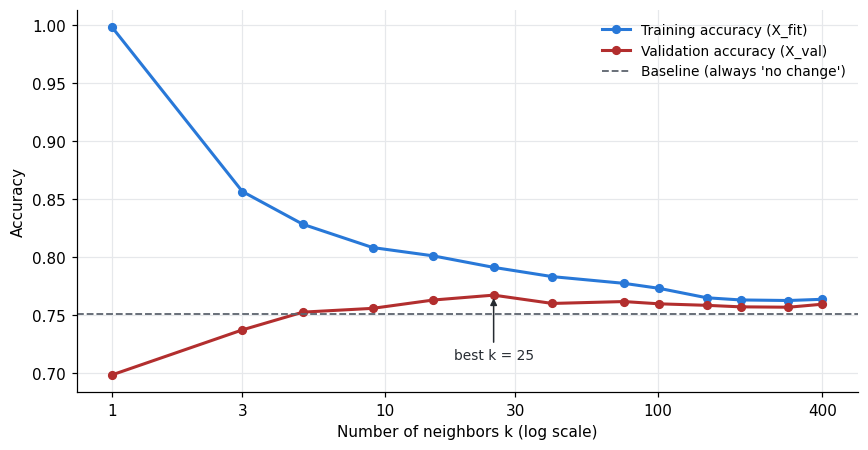

,k,Training accuracy,Validation accuracy
0,1,0.998,0.698
1,3,0.857,0.737
2,5,0.828,0.752
3,9,0.808,0.756
4,15,0.801,0.763
5,25,0.791,0.767
6,41,0.783,0.760
7,75,0.777,0.762
8,101,0.773,0.760
9,151,0.765,0.758


Bestes k: 25


In [10]:
k_values = [1, 3, 5, 9, 15, 25, 41, 75, 101, 151, 201, 301, 401]
train_accuracies = {}
val_accuracies = {}

for k in k_values:
    knn = make_knn(k)
    knn.fit(X_fit, y_fit)
    # Accuracy auf bekannten Daten
    train_accuracies[k] = knn.score(X_fit, y_fit)
    # Accuracy auf unbekannten Daten: nur diese zählt für die Auswahl
    val_accuracies[k] = knn.score(X_val, y_val)

# Das k mit der höchsten Accuracy auf den Prüfdaten
best_k = max(val_accuracies, key=val_accuracies.get)

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(k_values, list(train_accuracies.values()), "-o", ms=5, color=BLUE, label="Training accuracy (X_fit)")
ax.plot(k_values, list(val_accuracies.values()), "-o", ms=5, color=RED, label="Validation accuracy (X_val)")
ax.axhline(baseline_accuracy, color="#5F6670", ls="--", lw=1.2, label="Baseline (always 'no change')")
ax.annotate(f"best k = {best_k}", xy=(best_k, val_accuracies[best_k]), xytext=(0, -42),
            textcoords="offset points", ha="center", color=INK, fontsize=9,
            arrowprops=dict(arrowstyle="-|>", color=INK))
# Logarithmische Achse wie auf Folie 22: Die kleinen k werden besser sichtbar
ax.set_xscale("log")
ax.set_xticks([1, 3, 10, 30, 100, 400], labels=["1", "3", "10", "30", "100", "400"])
ax.minorticks_off()
ax.set_xlabel("Number of neighbors k (log scale)")
ax.set_ylabel("Accuracy")
ax.legend(loc="upper right", fontsize=9)
plt.tight_layout()
plt.show()

display(pd.DataFrame({"k": k_values,
                      "Training accuracy": list(train_accuracies.values()),
                      "Validation accuracy": list(val_accuracies.values())}).round(3))
print("Bestes k:", best_k)

**So liest du die Grafik**

- **x-Achse:** die Anzahl der Nachbarn k, logarithmisch wie auf Folie 22. Der Weg von 100 bis 400 ist also genauso lang wie der von 1 bis 4.
- **Blaue Linie ("Training accuracy"):** Accuracy auf den Daten, mit denen das Modell gelernt hat.
- **Rote Linie ("Validation accuracy"):** Accuracy auf den Prüfdaten. **Nur sie zählt für die Auswahl.**
- **Gestrichelte Linie ("Baseline"):** die Baseline. Darunter ist das Modell schlechter als immer "kein Wechsel" zu sagen.
- **Abstand zwischen Blau und Rot:** Je größer er ist, desto mehr lernt das Modell auswendig.

**Beispiel:** Bei k = 1 steht Blau bei 99,8 % und Rot bei 69,8 %, der Abstand von 30 Prozentpunkten zeigt starkes Overfitting. Bei k = 25 sind es 79,1 % und 76,7 %, der Abstand beträgt nur noch 2,4 Prozentpunkte.

**So lesen wir das Ergebnis (wie Folie 23):**

- **Links, kleines k: Overfitting.** Blau ist sehr hoch, Rot niedrig, die Lücke ist groß.
- **Mitte: das beste k.** Die rote Linie erreicht bei **k = 25** mit 76,7 % ihr Maximum.
- **Rechts, großes k: leichtes Underfitting.** Beide Linien sinken und laufen bei etwa 76 % zusammen. Das Modell wird zu grob.

**Aber Vorsicht:** Die Werte zwischen k = 15 und k = 101 liegen alle nah beieinander, zwischen 76,0 % und 76,7 %. Der Gipfel bei k = 25 beruht außerdem auf einer einzigen Aufteilung. Ob er stabil ist, prüft Schritt 8.

## 8. Cross-Validation (Folien 31 bis 36, DataCamp Kap. 2)

Das beste k beruht auf **einer** Aufteilung in `X_fit` und `X_val`. Folie 31 zeigt aber: Das Ergebnis hängt davon ab, welche Personen zufällig im Prüfteil gelandet sind.

**5-fache Cross-Validation:** Die Trainingsdaten werden in fünf Teile geschnitten. Jeder Teil dient genau einmal zur Prüfung, während das Modell auf den anderen vier neu lernt. Wir berichten **Mittelwert und Streuung** der fünf Ergebnisse.

```text
Runde 1:  [PRÜFEN] [lernen] [lernen] [lernen] [lernen]
Runde 2:  [lernen] [PRÜFEN] [lernen] [lernen] [lernen]
...
Runde 5:  [lernen] [lernen] [lernen] [lernen] [PRÜFEN]
```

Wir prüfen damit, ob das gewählte k auch über fünf verschiedene Aufteilungen hinweg gut abschneidet. Zum Vergleich steht k = 15 aus Schritt 6 daneben.

In [11]:
# Bauplan für 5 Folds: vorher mischen, fester Zufall (wie in DataCamp Kap. 2)
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

for k in [15, best_k]:
    # Fünfmal lernen und prüfen auf allen Trainingsdaten. Die Pipeline skaliert in jeder Runde neu
    cv_scores = cross_val_score(make_knn(k), X_train, y_train, cv=kf)
    print(f"k = {k:>3}: Accuracy je Fold {np.round(cv_scores, 3)}")
    print(f"         Mittelwert {cv_scores.mean():.3f} ± {cv_scores.std():.3f}")

k =  15: Accuracy je Fold [0.765 0.774 0.765 0.758 0.78 ]
         Mittelwert 0.769 ± 0.008
k =  25: Accuracy je Fold [0.762 0.778 0.766 0.762 0.782]
         Mittelwert 0.770 ± 0.009


**Ergebnis:**

| k | Accuracy (Mittelwert ± Streuung) | schlechtester Fold |
|---|---|---|
| 15 | 76,9 % ± 0,8 | 75,8 % |
| **25** | **77,0 % ± 0,9** | 76,2 % |

- **k = 25 ist stabil:** In allen fünf Folds liegt die Accuracy über der Baseline von 75,1 %.
- **k = 15 und k = 25 sind praktisch gleich gut:** Der Unterschied von 0,1 Prozentpunkten ist viel kleiner als die Streuung. Wir bleiben nach unserer Regel bei k = 25.
- Die Streuung von knapp einem Prozentpunkt zeigt, wie stark ein einzelnes Ergebnis vom Zufall der Aufteilung abhängt. Das ist der Grund für die Cross-Validation (Folie 31).

## 9. Die Schwelle wählen (Folien 57 bis 71)

### Wahrscheinlichkeiten statt Ja/Nein (Folie 57)

kNN kann für jede Person ausgeben, **welcher Anteil ihrer k Nachbarn wechseln will**. Das ist die vorhergesagte Wahrscheinlichkeit, `predict_proba`. `predict` sagt "Wechsel", sobald dieser Anteil mindestens 0,5 beträgt.

Die 0,5 ist aber nur eine Voreinstellung. **Die Schwelle ist eine geschäftliche Entscheidung, keine Eigenschaft des Modells** (Folien 58 bis 61). Auch hier nutzen wir die Prüfdaten `X_val`, damit das Testset unberührt bleibt.

In [12]:
# Modell mit dem besten k auf den Lerndaten
knn_best = make_knn(best_k)
knn_best.fit(X_fit, y_fit)

# Spalte 1 = Wahrscheinlichkeit für "Wechsel"
val_proba = knn_best.predict_proba(X_val)[:, 1]
print("Wahrscheinlichkeiten der ersten fünf Personen:", val_proba[:5].round(2))

Wahrscheinlichkeiten der ersten fünf Personen: [0.12 0.   0.56 0.48 0.16]


### Eine Schwelle, eine Confusion Matrix (Folie 62)

Für jede Schwelle entsteht eine eigene Confusion Matrix und damit eigene Kennzahlen:

- **Precision** = TP / (TP + FP): Von den Markierten, wie viele wollen wirklich wechseln?
- **Recall** = TP / (TP + FN): Von allen Wechselwilligen, wie viele finden wir?
- **F1:** harmonisches Mittel aus Precision und Recall

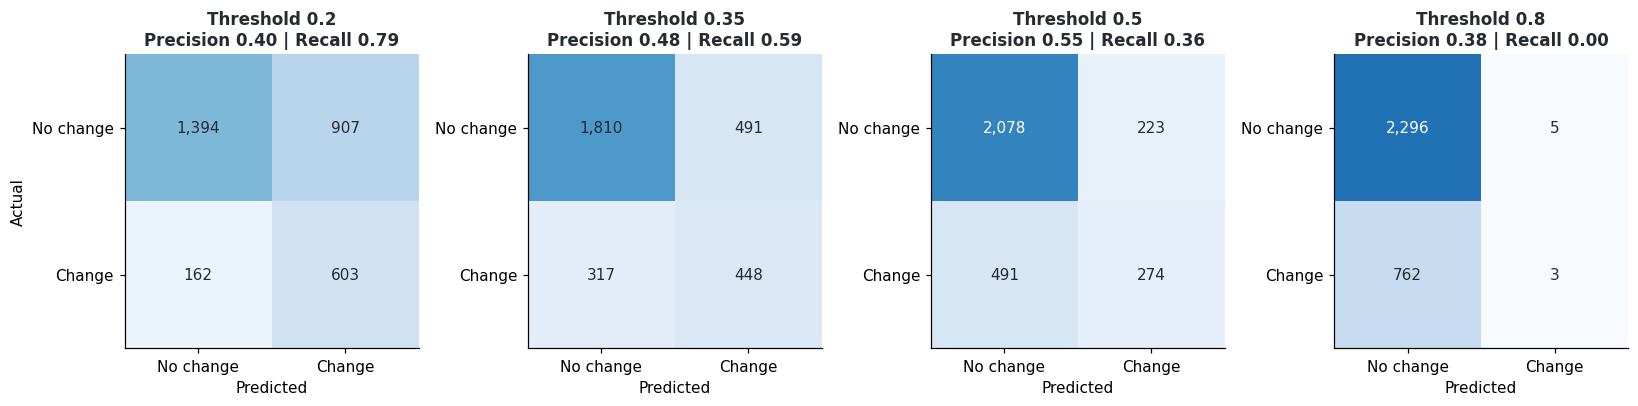

,Threshold,TN,FP,FN,TP,Accuracy,Precision,Recall,F1
0,0.20,1394,907,162,603,0.651,0.399,0.788,0.530
1,0.35,1810,491,317,448,0.736,0.477,0.586,0.526
2,0.50,2078,223,491,274,0.767,0.551,0.358,0.434
3,0.80,2296,5,762,3,0.750,0.375,0.004,0.008


In [13]:
# Die vier Schwellen von Folie 62
example_thresholds = [0.2, 0.35, 0.5, 0.8]

# Vier Confusion Matrices nebeneinander, eine je Schwelle
fig, axes = plt.subplots(1, 4, figsize=(15, 4.2))
rows = []

for ax, t in zip(axes, example_thresholds):
    # Alle ab der Schwelle als "Change" markieren
    pred = (val_proba >= t).astype(int)

    # ravel liest die Matrix zeilenweise aus: TN, FP, FN, TP
    tn, fp, fn, tp = confusion_matrix(y_val, pred).ravel()
    precision = tp / (tp + fp) if tp + fp > 0 else 0
    recall = tp / (tp + fn)
    f1 = 2 * precision * recall / (precision + recall) if precision + recall > 0 else 0
    rows.append({"Threshold": t, "TN": tn, "FP": fp, "FN": fn, "TP": tp,
                 "Accuracy": (tp + tn) / len(y_val), "Precision": precision, "Recall": recall, "F1": f1})

    # Zeichnet die Matrix: Zeilen = Wahrheit, Spalten = Vorhersage (wie Folie 42)
    # vmin/vmax: gleiche Farbskala in allen vier Bildern, damit die Farben vergleichbar sind
    disp = ConfusionMatrixDisplay.from_predictions(
        y_val, pred, ax=ax, cmap="Blues", colorbar=False, values_format=",d",
        display_labels=["No change", "Change"], im_kw={"vmin": 0, "vmax": len(y_val)})
    # Schriftfarbe passend zur gemeinsamen Farbskala: weiß auf dunklen, dunkel auf hellen Feldern
    for text, value in zip(disp.text_.ravel(), disp.confusion_matrix.ravel()):
        text.set_color("white" if value > 0.6 * len(y_val) else INK)
    ax.grid(False)
    ax.set_title(f"Threshold {t}\nPrecision {precision:.2f} | Recall {recall:.2f}",
                 color=INK, fontsize=11, fontweight="bold")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual" if t == example_thresholds[0] else "")

plt.tight_layout()
plt.show()

# Dieselben Werte als Tabelle zum genauen Ablesen
display(pd.DataFrame(rows).round(3))

**So liest du die Grafik**

- **Jedes Bild** ist eine Confusion Matrix für eine Schwelle, aufgebaut wie auf Folie 42.
- **Zeilen ("Actual"):** was wirklich passiert ist. **Spalten ("Predicted"):** was das Modell vorhergesagt hat.
- **Oben links:** richtig als "No change" erkannt (True Negative). **Unten rechts:** richtig als "Change" erkannt (True Positive).
- **Oben rechts:** Fehlalarm (False Positive). **Unten links:** übersehene Person (False Negative).
- **Farbe:** Je dunkler ein Feld, desto mehr Personen enthält es. Alle vier Bilder nutzen dieselbe Farbskala.

**Beispiel:** Bei **Threshold 0.5** stehen unten rechts 274 gefundene und unten links 491 übersehene Wechselwillige. Der Recall ist also 274 / (274 + 491) = 0,36. In der rechten Spalte stehen 274 richtige und 223 falsche Markierungen, die Precision ist 274 / (274 + 223) = 0,55.

**Von links nach rechts** steigt die Schwelle, und es werden immer weniger Personen als "Change" markiert. Die rechte Spalte wird dadurch heller, die linke dunkler: Die Fehlalarme sinken von 907 auf 5, die übersehenen Personen steigen von 162 auf 762.

**Was die Matrizen zeigen:**

- **Schwelle 0,5:** Das Modell findet nur 274 von 765 Wechselwilligen, der Recall liegt bei 35,8 %.
- **Schwelle 0,2:** Es findet 603 von 765 (Recall 78,8 %). Dafür steigen die Fehlalarme von 223 auf 907, nur noch 39,9 % der Markierten wollen wirklich wechseln.
- **Schwelle 0,8:** Fast niemand wird markiert, nur 8 Personen. Bei k = 25 haben kaum Personen 80 % wechselnde Nachbarn.

**Keine Schwelle gewinnt bei allen Kennzahlen** (Folie 62): Die Accuracy ist bei 0,5 am höchsten, der Recall bei 0,2. Deshalb brauchen wir einen Blick über alle Schwellen und eine Regel für die Wahl.

### ROC-Kurve und AUC (Folien 63 bis 69)

Statt vier Schwellen nehmen wir jetzt **alle**. Für jede Schwelle tragen wir einen Punkt ein:

- **x-Achse:** False Positive Rate = FP / alle Nichtwechsler, also der Anteil der Fehlalarme
- **y-Achse:** True Positive Rate = Recall, also der Anteil der gefundenen Wechsler

Die Punkte verbunden ergeben die **ROC-Kurve**. Die Fläche darunter heißt **AUC**. Sie bewertet das Modell über alle Schwellen hinweg: 1,0 ist perfekt, 0,5 ist Raten.

**Hier wählen wir noch keine Schwelle.** Die ROC-Kurve zeigt nur, **welche Kombinationen** aus gefundenen Wechslern und Fehlalarmen überhaupt möglich sind. Welcher Punkt auf der Kurve der beste ist, hängt davon ab, wie teuer die beiden Fehler sind. Das entscheiden erst die Kosten im nächsten Abschnitt.

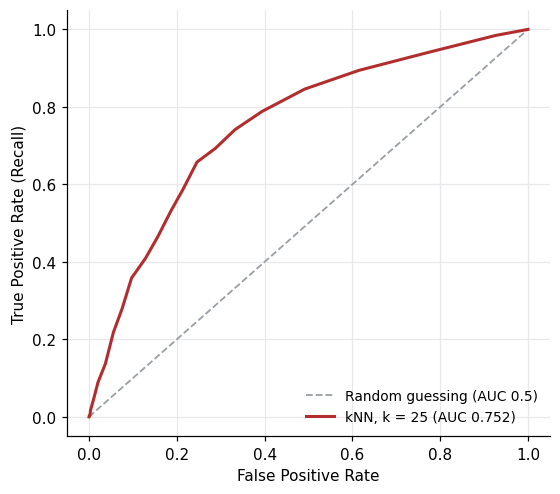

AUC on X_val: 0.752


In [14]:
# Für alle Schwellen: Anteil Fehlalarme (fpr) und Anteil gefundener Wechsler (tpr)
fpr, tpr, _ = roc_curve(y_val, val_proba)
val_auc = roc_auc_score(y_val, val_proba)

fig, ax = plt.subplots(figsize=(5.2, 4.6))
ax.plot([0, 1], [0, 1], ls="--", lw=1.2, color="#9AA0A6", label="Random guessing (AUC 0.5)")
ax.plot(fpr, tpr, color=RED, label=f"kNN, k = {best_k} (AUC {val_auc:.3f})")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate (Recall)")
ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()
print(f"AUC on X_val: {val_auc:.3f}")

**So liest du die Grafik**

- **x-Achse:** Anteil der Nichtwechsler, die fälschlich markiert werden. Nach rechts ist schlecht.
- **y-Achse:** Anteil der Wechselwilligen, die gefunden werden. Nach oben ist gut.
- **Jede Stelle auf der Kurve** ist eine Schwelle: links unten wird niemand markiert (Schwelle 1,0), rechts oben alle (Schwelle 0).
- **Gestrichelte Diagonale ("Random guessing"):** reines Raten. Je weiter die rote Kurve darüber liegt, desto besser trennt das Modell.

**Beispiel:** Die Confusion Matrices oben sind Punkte auf dieser Kurve. Bei Threshold 0.35 werden 491 von 2.301 Nichtwechslern fälschlich markiert (x ≈ 0,21) und 448 von 765 Wechslern gefunden (y ≈ 0,59). Bei Threshold 0.2 sind es x ≈ 0,39 und y ≈ 0,79. Wer mehr Wechsler finden will, wandert auf der Kurve also nach rechts oben und nimmt mehr Fehlalarme in Kauf.

Die Kurve ist eckig, weil bei k = 25 nur 26 verschiedene Anteile möglich sind (0/25, 1/25, ... 25/25).

**AUC = 0,752:** Zieht man zufällig eine Person, die wechselt, und eine, die nicht wechselt, gibt das Modell in rund 75 % der Fälle der wechselnden die höhere Wahrscheinlichkeit (Folie 69).

### Fehler haben Preise (Folien 70 und 71)

Die ROC-Kurve zeigt alle Möglichkeiten. Welche Schwelle wir nehmen, entscheiden die **Kosten der Fehler**. Wie in der Vorlesung sind die Beträge eine **Annahme**:

| Fehler | Bedeutung | Annahme |
|---|---|---|
| False Positive | Recruiting spricht jemanden an, der nicht wechseln will | 100 € |
| False Negative | Wechselwillige Person wird übersehen | 300 € |

Wir berechnen für jede Schwelle die Gesamtkosten der Fehler und nehmen die günstigste. Die Theorie von Folie 71 gibt als Richtwert: 100 / (100 + 300) = 0,25.

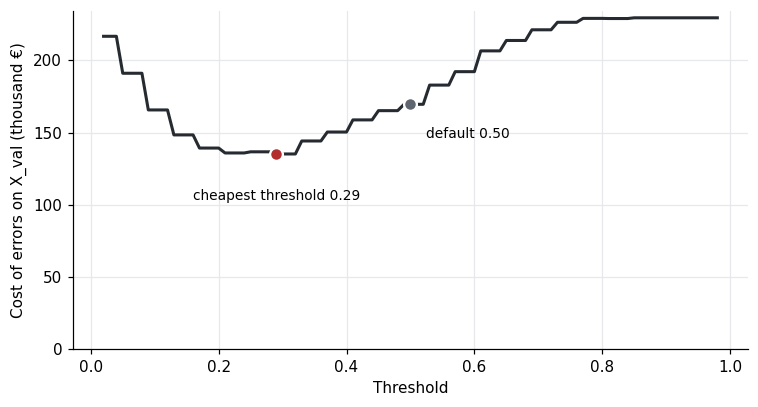

Theorie: 0.25 | günstigste Schwelle: 0.29
Kosten bei 0.50: 169,600 € | bei 0.29: 135,200 €


In [15]:
COST_FP, COST_FN = 100, 300     # Annahmen: hier anpassen, wenn ihr andere Kosten begründet

thresholds = np.round(np.arange(0.02, 0.99, 0.01), 2)
costs = []
for t in thresholds:
    tn, fp, fn, tp = confusion_matrix(y_val, (val_proba >= t).astype(int)).ravel()
    # Nur Fehler kosten Geld
    costs.append(fp * COST_FP + fn * COST_FN)
costs = np.array(costs)

# Schwelle mit den niedrigsten Kosten
best_threshold = float(thresholds[costs.argmin()])
cost_05 = costs[thresholds == 0.5][0]

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(thresholds, costs / 1000, color=INK)
ax.scatter([best_threshold], [costs.min() / 1000], s=70, color=RED, zorder=3, edgecolor="white", linewidth=1.5)
ax.scatter([0.5], [cost_05 / 1000], s=70, color="#5F6670", zorder=3, edgecolor="white", linewidth=1.5)
ax.annotate(f"cheapest threshold {best_threshold:.2f}", (best_threshold, costs.min() / 1000),
            xytext=(0, -30), textcoords="offset points", ha="center", fontsize=9)
ax.annotate("default 0.50", (0.5, cost_05 / 1000), xytext=(10, -22), textcoords="offset points", fontsize=9)
ax.set_xlabel("Threshold")
ax.set_ylabel("Cost of errors on X_val (thousand €)")
ax.set_ylim(0, None)
plt.tight_layout()
plt.show()

print(f"Theorie: {COST_FP / (COST_FP + COST_FN):.2f} | günstigste Schwelle: {best_threshold:.2f}")
print(f"Kosten bei 0.50: {cost_05:,} € | bei {best_threshold:.2f}: {costs.min():,} €")

**So liest du die Grafik**

- **x-Achse:** die Schwelle. **y-Achse:** die gesamten Fehlerkosten auf `X_val`. Je niedriger die Linie, desto besser.
- **Roter Punkt ("cheapest threshold"):** die günstigste Schwelle. **Grauer Punkt ("default 0.50"):** die Standard-Schwelle 0,5.
- **Stufen:** Die Linie springt nur an bestimmten Stellen, weil bei k = 25 die Wahrscheinlichkeiten in Schritten von 0,04 liegen. Zwischen zwei solchen Werten ändert sich nichts.

**Beispiel:** Ganz rechts wird niemand angesprochen, dann werden alle 765 Wechselwilligen übersehen: 765 · 300 € = 229.500 €. Ganz links werden fast alle angesprochen, dann entstehen sehr viele Fehlalarme. Das Minimum liegt dazwischen.

**Ergebnis:** Die günstigste Schwelle ist **0,29**. Die Fehlerkosten auf `X_val` sinken damit von 169.600 € auf 135.200 €.

Sie liegt nah am Richtwert von 0,25. Zwischen etwa 0,21 und 0,32 sind die Kosten fast gleich, die genaue Schwelle ist also nicht kritisch. Die Beträge von 100 € und 300 € sind eine Annahme: Für die Schwelle zählt nur ihr Verhältnis von 1 : 3.

## 10. Abschlussprüfung auf dem Testset (Folien 42 bis 52, 63 bis 69)

Jetzt ist alles festgelegt: k und Schwelle. Das endgültige Modell lernt auf **allen** 15.326 Trainingspersonen und wird genau einmal auf dem Testset geprüft. Danach ändern wir nichts mehr.

Test AUC: 0.786


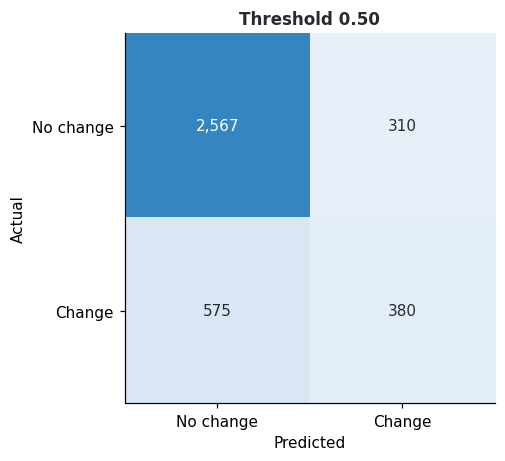

=== Default threshold 0.50 ===
              precision    recall  f1-score   support

   No change      0.817     0.892     0.853      2877
      Change      0.551     0.398     0.462       955

    accuracy                          0.769      3832
   macro avg      0.684     0.645     0.657      3832
weighted avg      0.751     0.769     0.756      3832

Cost of errors: 203,500 €

=== Cost-based threshold 0.29 ===
              precision    recall  f1-score   support

   No change      0.890     0.756     0.818      2877
      Change      0.495     0.719     0.586       955

    accuracy                          0.747      3832
   macro avg      0.693     0.738     0.702      3832
weighted avg      0.792     0.747     0.760      3832

Cost of errors: 150,500 €

Baseline: accuracy 0.751, cost of errors 286,500 €


In [16]:
# Endgültiges Modell: bestes k, alle Trainingsdaten
final_model = make_knn(best_k)
final_model.fit(X_train, y_train)

# Spalte 1 = Wahrscheinlichkeit für "Wechsel"
test_proba = final_model.predict_proba(X_test)[:, 1]
print(f"Test AUC: {roc_auc_score(y_test, test_proba):.3f}")

# Die zwei Schwellen, die wir vergleichen
rules = [("Default threshold 0.50", 0.5), (f"Cost-based threshold {best_threshold:.2f}", best_threshold)]

# Confusion Matrix für die Standard-Schwelle 0.50
pred_05 = (test_proba >= 0.5).astype(int)

fig, ax = plt.subplots(figsize=(5, 4.3))
# Zeilen = Wahrheit, Spalten = Vorhersage (wie Folie 42)
disp = ConfusionMatrixDisplay.from_predictions(
    y_test, pred_05, ax=ax, cmap="Blues", colorbar=False, values_format=",d",
    display_labels=["No change", "Change"], im_kw={"vmin": 0, "vmax": len(y_test)})
# Schriftfarbe passend zur Farbskala: weiß auf dunklen, dunkel auf hellen Feldern
for text, value in zip(disp.text_.ravel(), disp.confusion_matrix.ravel()):
    text.set_color("white" if value > 0.6 * len(y_test) else INK)
ax.grid(False)
ax.set_title("Threshold 0.50", color=INK, fontsize=11, fontweight="bold")
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

# Precision, Recall und F1 je Klasse (Folie 52: classification_report) und die Kosten
for name, t in rules:
    pred = (test_proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    print(f"=== {name} ===")
    print(classification_report(y_test, pred, target_names=["No change", "Change"], digits=3))
    print(f"Cost of errors: {fp * COST_FP + fn * COST_FN:,} €\n")

# Zum Vergleich: die Baseline übersieht alle Wechsler
print(f"Baseline: accuracy {1 - y_test.mean():.3f}, cost of errors {int(y_test.sum()) * COST_FN:,} €")

**So liest du die Grafik**

- **Zeilen ("Actual"):** was wirklich passiert ist. **Spalten ("Predicted"):** was das Modell vorhergesagt hat.
- **Unten rechts:** gefundene Wechsler (True Positive). **Unten links:** übersehene Wechsler (False Negative).
- **Oben rechts:** Fehlalarme (False Positive). **Oben links:** richtig erkannte Nichtwechsler (True Negative).

**Beispiel:** Das Modell findet 380 von 955 Wechselwilligen und übersieht 575. Von den 690 markierten Personen wollen 380 wirklich wechseln, 310 sind Fehlalarme. Daraus folgen ein Recall von 380 / 955 = 0,40 und eine Precision von 380 / 690 = 0,55.

### Ergebnis auf dem Testset

| Regel | Accuracy | Precision | Recall | F1 | Kosten |
|---|---|---|---|---|---|
| Baseline | 75,1 % | 0 | 0 | 0 | 286.500 € |
| kNN, Schwelle 0,50 | 76,9 % | 55,1 % | 39,8 % | 0,46 | 203.500 € |
| kNN, Schwelle 0,29 | 74,7 % | 49,5 % | 71,9 % | 0,59 | 150.500 € |

So entstehen die Zahlen, zum Beispiel bei Schwelle 0,50:

```text
Accuracy  = (2.567 + 380) / 3.832  = 76,9 %
Precision = 380 / (380 + 310)      = 55,1 %
Recall    = 380 / (380 + 575)      = 39,8 %
Kosten    = 310 · 100 € + 575 · 300 € = 203.500 €
```

- **Schwelle 0,50:** Das Modell schlägt die Baseline bei der Accuracy nur knapp und findet 380 von 955 Wechselwilligen.
- **Schwelle 0,29:** Es findet 687 von 955. Dafür steigen die Fehlalarme von 310 auf 701, ungefähr jede zweite angesprochene Person will wirklich wechseln.
- **Accuracy gegen Kosten:** Die Accuracy sinkt bei 0,29 sogar unter die Baseline. Die Kosten fallen aber um 26 % gegenüber der Schwelle 0,5 und um 47 % gegenüber der Baseline. Die Accuracy allein hätte uns zur schlechteren Entscheidung geführt.
- **Test-AUC 0,786:** Das ist etwas höher als die 0,752 auf `X_val`. Das endgültige Modell hat mit allen Trainingsdaten gelernt, also mit rund 25 % mehr Personen, und das Testset enthält andere Personen. Beides kann den Wert verschieben.

## 11. Fazit (Folie 76)

**Endgültiges Modell:** kNN mit **k = 25**, gemischtes Encoding, `StandardScaler`, Schwelle **0,29**.

| Erkenntnis | Beleg |
|---|---|
| Accuracy auf Trainingsdaten täuscht | k = 1: 99,8 % auf den Lerndaten, 69,8 % auf den Prüfdaten |
| k steuert Over- und Underfitting | beste Validierungs-Accuracy bei k = 25 (76,7 %) |
| Das Ergebnis ist stabil | 5-fache CV: 77,0 % ± 0,9, jeder Fold über der Baseline |
| Accuracy reicht bei seltenen Klassen nicht | die Baseline erreicht schon 75,1 % |
| Die Schwelle ist eine Geschäftsentscheidung | Kosten 150.500 € statt 203.500 € bei Schwelle 0,29 |
| Das Modell trennt die Klassen ordentlich | Test-AUC 0,786 |

**Grenzen:**

- Die Kosten von 100 € und 300 € sind eine Annahme.
- Das Modell findet zwar 72 % der Wechselwilligen, aber nur jede zweite Markierung stimmt.
- Für die Präsentation fehlt noch die logistische Regression als zweites Modell (Folie 78).

# 12. Export Test-Wahrscheinlichkeiten kNN

Hier wird eine pickle Datei erstellt mit den Werten zum Vergleich der Modelle und zur Visualisierung

In [18]:
pd.DataFrame({
    "student_id": test["student_id"].values,
    "y_true": y_test.values,
    "proba": test_proba,
}).to_pickle("pred_knn.pkl")